# Price-directed state-space search: an end-to-end example

The same pipeline as `cl_model.ipynb`, solved with the exact method of `offline_cl_PDS`
(the "clairvoyant benchmark" paper's price-directed state-space search):

1. **The instance** — six vehicles, all three cohorts.
2. **FIFO simulation** with a warm-up and a drain.
3. **The offline instance** and its closed-system horizon, read off FIFO's own schedule.
4. **Price-directed search** — the optimum, with a certificate.
5. **The same instance** solved by the compact MILP (`offline_cl_opt`) and by branch-and-price
   (`offline_cl_PB`): all three must agree.
6. **What the search did** — the bracket over time and the slot prices it searched with.
7. **The schedule**, plotted with `offline_cl_opt`'s functions.
8. **A larger instance** (15 vehicles, the sweep's station), where the compact MILP stalls.

How the method works, in five lines (details and the exactness argument: `offline_cl_PDS/README.md`):

* Column generation on a master problem gives **slot prices**: what holding a connector with `q`
  modules costs in each slot. Any non-negative prices give a valid lower bound on the optimum.
* The prices become exact **cost-to-go tables**: for every vehicle, the cheapest departure-plus-rent
  from any slot and energy. Summed over vehicles, they **bound every partial schedule** at the cost of
  one table lookup per vehicle.
* A **layered search** builds schedules one slot at a time (which vehicles to connect, how the modules
  are split), discards partial schedules whose bound reaches the best known schedule, and merges
  partial schedules that are dominated (same vehicles, less energy, more cost).
* Passes with **rising thresholds** either find a better schedule or prove that none exists below the
  threshold. The last one proves optimality.
* Everything runs on an exact energy and price grid that never under-states energy, so the bound is a
  certificate for the compact model itself; the schedule is replayed with the compact model's own
  dynamics and checked against every one of its rows.

## 1. The instance

One pile with two connectors sharing six 25 kW modules (150 kW) — `cl_model.ipynb`'s station and
vehicles. The warm-up runs for 12 minutes and arrivals are accepted for the following 60; the
simulation then drains the station.

- EVs **0, 1** plug in during warm-up and are still charging at the boundary → `BOUNDARY`
- EV **2** arrives during warm-up but both connectors are busy → `QUEUED`
- EVs **3, 4, 5** arrive inside the measured window → `MEASUREMENT`

In [1]:
import math

import numpy as np
import pandas as pd

from config import HR2MIN
from models.ev import EV
from env.charging_env import ChargingStationEnv
from policy.queue.fifo import FIFOQueuePolicy
from offline_cl_opt import StationSpec

WARMUP_MIN = 0.0    # warm-up: builds up a loaded station, then the measured window starts
MEASURE_MIN = 60.0   # arrival window after warm-up; the station is then drained
DELTA = 1.0          # slot length (minutes)
HORIZON_SLACK = 0.20 # horizon = FIFO's makespan on the grid * (1 + slack), as in the objective sweep

STATION = StationSpec(n_piles=1, n_connectors=2, n_modules=6, p_module=25.0)

# (id, arrival_min, battery_kWh, s_i, s_f) on the whole-run clock.
EV_SPECS = [
    (0,  0.0,  40.0, 0.20, 0.75),   # -> BOUNDARY
    (1,  3.0,  40.0, 0.25, 0.75),   # -> BOUNDARY
    (2, 11.0, 100.0, 0.20, 0.75),   # -> QUEUED
    (3, 20.0,  40.0, 0.20, 0.80),   # -> MEASUREMENT
    (4, 30.0, 100.0, 0.25, 0.80),   # -> MEASUREMENT
    #(5, 42.0,  35.0, 0.25, 0.70),   # -> MEASUREMENT
]
evs = [EV(id=i, c_b=kwh * HR2MIN, s_i=s_i, s_f=s_f, arrival_time=t) for (i, t, kwh, s_i, s_f) in EV_SPECS]

pd.DataFrame(EV_SPECS, columns=["id", "arrival", "battery_kWh", "s_i", "s_f"]).assign(
    energy_needed_kWh=lambda d: d.battery_kWh * (d.s_f - d.s_i),
    phase=lambda d: np.where(d.arrival < WARMUP_MIN, "warm-up", "measured"),
)

,id,arrival,battery_kWh,s_i,s_f,energy_needed_kWh,phase
0,0,0.0,40.0,0.20,0.75,22.0,measured
1,1,3.0,40.0,0.25,0.75,20.0,measured
2,2,11.0,100.0,0.20,0.75,55.0,measured
3,3,20.0,40.0,0.20,0.80,24.0,measured
4,4,30.0,100.0,0.25,0.80,55.0,measured


## 2. FIFO simulation

The discrete-event simulator with a first-come-first-served queue, warm-up and measured phase in one
episode, drained at the end. Its boundary snapshot is the offline models' initial condition.

In [2]:
env = ChargingStationEnv(
    n_piles=STATION.n_piles, n_connectors=STATION.n_connectors,
    n_modules=STATION.n_modules, p_module=STATION.p_module,
    queue_capacity=1000, mean_interarrival=None, arrivals=evs,
    max_time=MEASURE_MIN, warmup_period=WARMUP_MIN, drain=True,
)
obs, _ = env.reset(seed=0)
rng, policy, done = np.random.default_rng(1), FIFOQueuePolicy(), False
while not done:
    ev, pile_id = policy.decide(obs, env.action_masks(), rng, env.engine.station)
    obs, _, done, _, _ = env.step(pile_id, ev=ev)

m = env.engine.metrics
print(f"episode clock = {env.engine.current_time:.1f} min; arrived={len(m.arrived_evs)} "
      f"finished={len(m.finished_evs)} dropped={len(m.dropped_evs)}")
print(f"\nAt the boundary (t={WARMUP_MIN:.0f}):")
for s in m.in_service_at_warmup_end:
    print(f"  BOUNDARY    EV {s.ev_id}: SoC {s.s_i:.2f} -> {s.s_current:.3f} (target {s.s_f:.2f})")
for ev in m.queued_at_warmup_end:
    print(f"  QUEUED      EV {ev.id} waiting since t={ev.arrival_time:.0f}")
for ev in m.arrived_post_warmup:
    print(f"  MEASUREMENT EV {ev.id} arrives at t={ev.arrival_time:.0f}")

# --- FIFO's own schedule -------------------------------------------------------
fifo = pd.DataFrame([
    {"ev_id": ev.id, "arrival": ev.arrival_time,
     "service_start": ev.service_start_time, "departure": ev.departure_time,
     "wait": ev.service_start_time - ev.arrival_time,
     "sojourn": ev.departure_time - ev.arrival_time}
    for ev in sorted(m.finished_evs, key=lambda e: e.id)
])
print()
display(fifo)

# Sojourn per cohort after the boundary. The boundary/queued vehicles are clocked
# from the BOUNDARY, not their real arrival, so these are directly comparable
# with the offline models below (which place those vehicles at a=0).
sim_by_cohort = m.sojourn_by_cohort(since=m.warmup_period)
print("FIFO mean sojourn after the boundary:")
for name, s in sim_by_cohort.items():
    print(f"  {name:20s} n={int(s['n'])}  mean={s['mean_sojourn']:6.2f} min")

episode clock = 79.1 min; arrived=5 finished=5 dropped=0

At the boundary (t=0):
  MEASUREMENT EV 0 arrives at t=0
  MEASUREMENT EV 1 arrives at t=3
  MEASUREMENT EV 2 arrives at t=11
  MEASUREMENT EV 3 arrives at t=20
  MEASUREMENT EV 4 arrives at t=30



,ev_id,arrival,service_start,departure,wait,sojourn
0,0,0.0,0.000000,21.996744,0.000000,21.996744
1,1,3.0,3.000000,24.227765,0.000000,21.227765
2,2,11.0,21.996744,49.716893,10.996744,38.716893
3,3,20.0,24.227765,76.306183,4.227765,56.306183
4,4,30.0,49.716893,79.053626,19.716893,49.053626


FIFO mean sojourn after the boundary:
  measurement          n=5  mean= 37.46 min
  measurement_queued   n=5  mean= 37.46 min
  all                  n=5  mean= 37.46 min


## 3. The offline instance, grid-FIFO and the horizon

`build_measurement_instance` shifts arrivals so the measured window starts at `t=0`, keeps the queued
vehicles, and turns the plugged-in ones into `OPTIMIZE` boundary vehicles (lane pinned, energy resumes
from what they already have).

Two schedules come out of the FIFO run, and they play different roles:

* **Grid-FIFO** — the benchmark. FIFO's *own* timetable replayed on the slot grid: the lanes and the
  order FIFO's queue assigned, each stay rounded up to whole slots along its lane's handover chain
  (`metrics.grid_replay_intervals`), and power following the simulator's power-sharing rule
  (`grid_fifo_cl_model`). This is what FIFO achieves on the grid, and what the optimum is compared to
  (the `FIFO/grid` column in section 7 is the same replay).
* **The starting schedule** — only an incumbent for the solvers. `schedule_from_simulation` keeps FIFO's
  plug-in order and piles but re-times everything: each vehicle starts at the first slot with a free
  connector and charges as fast as the *remaining* whole modules allow (earlier vehicles first). That
  is a different power policy, so it is usually a little better than grid-FIFO; it is not FIFO.

The models are **closed-system** (every vehicle served and fully charged by the horizon), so, as in the
objective sweep (`closed_system_horizon`), the horizon covers both schedules' makespans plus a slack.

In [3]:
from offline_cl_opt import grid_fifo_cl_model
from offline_cl_opt.boundary import COHORTS_ALL, BoundaryMode, build_measurement_instance
from offline_cl_opt.model import sojourn_minutes
from offline_cl_opt.solution import extract_solution
from offline_cl_PB import schedule_from_simulation


def measurement_instance(horizon_minutes):
    return build_measurement_instance(
        arrived_post_warmup=m.arrived_post_warmup,
        queued_at_warmup_end=m.queued_at_warmup_end,
        in_service_at_warmup_end=m.in_service_at_warmup_end,
        warmup_period=WARMUP_MIN, delta=DELTA, horizon_minutes=horizon_minutes,
        include_queued=True, boundary_mode=BoundaryMode.OPTIMIZE, station=STATION,
    )


# Grid-FIFO's makespan: the slot by which FIFO's replayed timetable empties the station.
K_grid = max(m.grid_departure_slots(DELTA, since=WARMUP_MIN).values())

# The starting schedule, built on a generous provisional horizon.
K_try = 2 * max(K_grid, math.ceil((env.engine.current_time - WARMUP_MIN) / DELTA))
inst = measurement_instance(K_try * DELTA)
start_schedule, counts = schedule_from_simulation(
    m.arrived_evs, inst.vehicles, STATION, DELTA, K_try, inst.boundary_vehicles, warmup_period=WARMUP_MIN,
)
assert start_schedule is not None, counts
K_start = max(p.departure for p in start_schedule.values())

# Horizon: both makespans plus the slack (the objective sweep's rule).
K = math.ceil(max(K_grid, K_start) * (1 + HORIZON_SLACK))
HORIZON_MIN = K * DELTA
inst = measurement_instance(HORIZON_MIN)

# Grid-FIFO as a solved compact model: its objective is FIFO's total sojourn on the grid.
cl_model_fifo, fifo_fit = grid_fifo_cl_model(m, inst, STATION, DELTA, HORIZON_MIN)
grid_fifo_total = extract_solution(cl_model_fifo).objective
start_total = sum(sojourn_minutes(start_schedule[v.id].departure, v.a, DELTA) for v in inst.vehicles)

print(f"J={len(inst.vehicles)} vehicles, cohorts {({j: c.value for j, c in sorted(inst.cohorts.items())})}")
print(f"horizon K={K} slots ({HORIZON_MIN:g} min): grid-FIFO makespan {K_grid}, starting schedule makespan {K_start}")
print(f"grid-FIFO (FIFO's assignment and power sharing): total sojourn {grid_fifo_total:.1f} min "
      f"(power moved to fit the grid: {fifo_fit['total_abs_deviation_kwh']:.2f} kWh)")
print(f"starting schedule (FIFO's order, re-timed):      total sojourn {start_total:.1f} min  {counts}")

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2616613
Academic license 2616613 - for non-commercial use only - registered to m.___@mail.utoronto.ca
J=5 vehicles, cohorts {0: 'measurement', 1: 'measurement', 2: 'measurement', 3: 'measurement', 4: 'measurement'}
horizon K=102 slots (102 min): grid-FIFO makespan 80, starting schedule makespan 85
grid-FIFO (FIFO's assignment and power sharing): total sojourn 191.0 min (power moved to fit the grid: 1.45 kWh)
starting schedule (FIFO's order, re-timed):      total sojourn 186.0 min  {'followed_simulation': 5, 'moved': 0, 'unplaceable': 0, 'not_started_in_simulation': 0}


## 4. Price-directed search

`progress=True` prints each stage: the column generation rounds (master LP value `z_RMP` and the
Lagrangian bound `L`, in slots; `L` is very poor in the first rounds, while the prices are still far
from the optimal duals, and rises to meet `z_RMP`), the cost-to-go tables, the **beam** passes (keep only
the best partial schedules per slot — a fast heuristic that still certifies a bound) and the **exact**
passes. Every pass reports what it certifies: no schedule has a total sojourn below `certified LB`.

`master="auto"` uses the aggregate master for one pile (connectors and modules counted per slot) and
the stronger configuration master from two piles on.

In [6]:
from offline_cl_PDS import solve_price_directed_search

pds = solve_price_directed_search(
    inst.vehicles, STATION, DELTA, HORIZON_MIN,
    boundary_vehicles=inst.boundary_vehicles,
    cohorts=inst.cohorts,
    objective_cohorts=COHORTS_ALL,
    #initial_schedule=start_schedule,
    master="auto",
    time_limit=600,
    progress=True,
)

print(f"\nstatus={pds.status}: objective (total sojourn) = {pds.objective:.1f} min, "
      f"certified lower bound = {pds.lower_bound:.1f} min, mean sojourn {pds.mean_sojourn:.2f} min")
print(f"master bound {pds.master_bound:.2f} min, bound at the empty schedule {pds.root_lower_bound:.1f} min")
print(f"compact-model row check: max violation {pds.compact_check.max_violation:.1e}; "
      f"table repairs {pds.table_repairs}; best schedule from: {pds.incumbent_source}")
print("seconds per stage:", {k: round(v, 2) for k, v in pds.timings.items()})
display(pd.DataFrame(pds.passes))
display(pds.per_vehicle)

[PDS     0.0s] incumbent 185 min from greedy list schedule
[PDS     0.1s] aggregate CG it 10: z_RMP=248.000 L=-268228.021 best L=-268228.021 added=10
[PDS     0.3s] aggregate CG it 20: z_RMP=245.664 L=-28689.674 best L=-28689.674 added=15
[PDS     0.7s] aggregate CG it 30: z_RMP=240.307 L=-2876.590 best L=-2876.590 added=13
[PDS     1.0s] aggregate CG it 40: z_RMP=238.578 L=-101.278 best L=-101.278 added=9
[PDS     1.3s] aggregate CG it 50: z_RMP=237.458 L=197.046 best L=197.046 added=7
[PDS     1.6s] aggregate CG it 60: z_RMP=235.389 L=228.930 best L=228.930 added=7
[PDS     2.0s] aggregate CG it 70: z_RMP=233.337 L=231.145 best L=231.400 added=6
[PDS     2.2s] aggregate CG it 80: z_RMP=232.778 L=231.942 best L=232.049 added=7
[PDS     2.5s] aggregate CG it 90: z_RMP=232.685 L=232.459 best L=232.459 added=4
[PDS     2.8s] aggregate CG it 100: z_RMP=232.660 L=232.587 best L=232.587 added=4
[PDS     3.1s] aggregate CG it 110: z_RMP=232.647 L=232.618 best L=232.623 added=3
[PDS     3.3s]

,kind,beam_width,threshold,found,certified_lower_bound,status,expanded,stored,peak_states,runtime_s
0,beam,200,185.0,172.0,172.0,memory cut,6526,9840,200,0.088754


,vehicle_id,cohort,boundary_mode,in_objective,arrival,served,pile,connector,start_slot,departure_slot,sojourn_min,energy_kwh,energy_delivered_before_kwh,energy_required_kwh
0,0,measurement,None,True,0.0,True,0,0,0.0,22.0,22.0,22.0,0.0,22.0
1,1,measurement,None,True,3.0,True,0,1,3.0,24.0,21.0,20.0,0.0,20.0
2,2,measurement,None,True,11.0,True,0,1,24.0,58.0,47.0,55.0,0.0,55.0
3,3,measurement,None,True,20.0,True,0,0,22.0,50.0,30.0,24.0,0.0,24.0
4,4,measurement,None,True,30.0,True,0,0,50.0,82.0,52.0,55.0,0.0,55.0


## 5. The same instance, solved by the other two exact methods

The compact MILP (`offline_cl_opt`, Gurobi) and branch-and-price (`offline_cl_PB`) solve the very same
model, so a proven optimum must be the same for all three; a method stopped by its time limit returns a
bracket `[lower bound, objective]` that must contain it. Each gets two minutes here (the compact model
usually needs most of them; branch-and-price usually stops with a bracket).

In [ ]:
import time

from offline_cl_opt import build_cl_model, solve_cl_model
from offline_cl_opt.solution import extract_solution
from offline_cl_PB import solve_branch_and_price

t0 = time.perf_counter()
cl_model = build_cl_model(inst.vehicles, STATION, DELTA, HORIZON_MIN, boundary_vehicles=inst.boundary_vehicles,
                          cohorts=inst.cohorts, objective_cohorts=COHORTS_ALL)
solve_cl_model(cl_model, mip_gap=0.0, time_limit=120)
compact = extract_solution(cl_model)
t_compact = time.perf_counter() - t0

t0 = time.perf_counter()
bp = solve_branch_and_price(inst.vehicles, STATION, DELTA, HORIZON_MIN, boundary_vehicles=inst.boundary_vehicles,
                            cohorts=inst.cohorts, objective_cohorts=COHORTS_ALL,
                            initial_schedule=start_schedule, time_limit=120)
t_bp = time.perf_counter() - t0

comparison = pd.DataFrame([
    {"method": "price-directed search", "status": pds.status, "objective": pds.objective,
     "lower bound": pds.lower_bound, "runtime_s": pds.runtime},
    {"method": "compact MILP", "status": compact.status, "objective": compact.objective,
     "lower bound": compact.best_bound, "runtime_s": t_compact},
    {"method": "branch-and-price", "status": bp.status, "objective": bp.objective,
     "lower bound": bp.lower_bound, "runtime_s": t_bp},
])
display(comparison)
for name, status, lower, upper in [("compact MILP", compact.status, compact.best_bound, compact.objective),
                                   ("branch-and-price", bp.status, bp.lower_bound, bp.objective)]:
    assert lower <= pds.objective + 1e-6 <= upper + 2e-6, f"{name}'s bracket must contain the optimum"
    if status == "OPTIMAL":
        assert abs(upper - pds.objective) < 1e-6, f"{name} proved a different optimum"
print("OK: every proven optimum equals the search's, and every bracket contains it")

## 6. What the search did

**The bracket over time.** The upper curve is the best schedule found so far, the lower curve the
certified lower bound; the solve is over when they meet. The dotted line is the master problem's
bound — the root of the search sits within one rounding of it.

**The slot prices.** The heat map is the rent the bound charges for holding a connector with `q`
modules in slot `k`; the bars are the most rent the whole station can pay in that slot. Prices are
positive only where the master problem finds connectors or modules scarce, which is where the
schedule has to make real choices.

In [ ]:
from offline_cl_PDS.visualization import plot_bound_history, plot_slot_prices

display(plot_bound_history(pds, references={"grid-FIFO": grid_fifo_total}))
display(plot_slot_prices(pds))

## 7. The schedule

`to_cl_model()` returns the schedule as a solved `offline_cl_opt` model, so `extract_solution` and every
`offline_cl_opt` plot work on it. Per cohort, against FIFO (continuous time, and grid-FIFO as in
`cl_model.ipynb`), then the optimal schedule's pile with grid-FIFO's below it:

In [ ]:
from offline_cl_opt import plot_pile_power_and_modules

cl_model_pds = pds.to_cl_model()
solution_pds = extract_solution(cl_model_pds)

censor_at = env.engine.current_time
grid = m.arrived_grid_sojourn_by_cohort(DELTA, since=m.warmup_period, censor_at=censor_at)
sim = m.arrived_sojourn_by_cohort(since=m.warmup_period, censor_at=censor_at)
print(f"{'cohort':22s} {'FIFO':>8s} {'FIFO/grid':>10s} {'OPT':>8s} {'n':>4s}")
for name, opt in solution_pds.by_cohort.items():
    print(f"{name:22s} {sim[name]['mean_sojourn']:8.2f} {grid[name]['mean_sojourn']:10.2f} "
          f"{opt['mean_sojourn']:8.2f} {int(opt['n']):4d}")
print(f"\ntotal sojourn: grid-FIFO {grid_fifo_total:.1f} min, optimum {pds.objective:.1f} min "
      f"({100 * (grid_fifo_total - pds.objective) / pds.objective:.1f}% above the optimum)")

display(plot_pile_power_and_modules(
    cl_model_pds, pile_id=0, stack_other_connectors=True, show_pile_capacity=True,
    title="Pile 0 (price-directed search): power by connector",
))
display(plot_pile_power_and_modules(
    cl_model_fifo, pile_id=0, stack_other_connectors=True, show_pile_capacity=True,
    title="Pile 0 (grid-FIFO): power by connector",
))

## 8. A larger instance

Fifteen vehicles on the objective sweep's default station (one pile, two connectors, 6 × 25 kW,
2-minute slots), Poisson arrivals every 12 minutes on average, batteries of 50/75/100 kWh charging at
up to 2C. No simulation here: the solvers start from `offline_cl_PB`'s greedy list schedule.

The compact MILP gets two minutes; the price-directed search is given ten but needs far less.

15 vehicles, K=161 slots of 2 min
[PDS     0.0s] incumbent 1184 min from greedy list schedule
[PDS     0.2s] aggregate CG it 10: z_RMP=1085.000 L=-536308.355 best L=-536308.355 added=45
[PDS     1.3s] aggregate CG it 20: z_RMP=1016.274 L=-56816.075 best L=-56816.075 added=32
[PDS     2.7s] aggregate CG it 30: z_RMP=982.228 L=-5235.651 best L=-5235.651 added=30
[PDS     3.8s] aggregate CG it 40: z_RMP=972.555 L=303.325 best L=303.325 added=12
[PDS     4.6s] aggregate CG it 50: z_RMP=971.656 L=899.483 best L=899.483 added=10
[PDS     5.6s] aggregate CG it 60: z_RMP=953.267 L=942.363 best L=942.363 added=11
[PDS     6.4s] aggregate CG it 70: z_RMP=950.039 L=947.740 best L=947.740 added=9
[PDS     7.2s] aggregate CG it 80: z_RMP=949.383 L=949.137 best L=949.137 added=4
[PDS     7.7s] aggregate master: Lagrangian bound 912.726 min after 88 rounds (stopped: z_RMP - L = 0.00267 min)
[PDS     8.4s] tables built (0.7s, 405200 breakpoints, 0 repairs); root bound 914 min
[PDS     8.6s] beam 200 T

,method,status,objective,lower bound,mean sojourn,runtime_s
0,price-directed search,OPTIMAL,958.0,958.000000,63.866667,9.475418
1,compact MILP (120 s),no schedule found,NaN,421.494296,NaN,120.489536


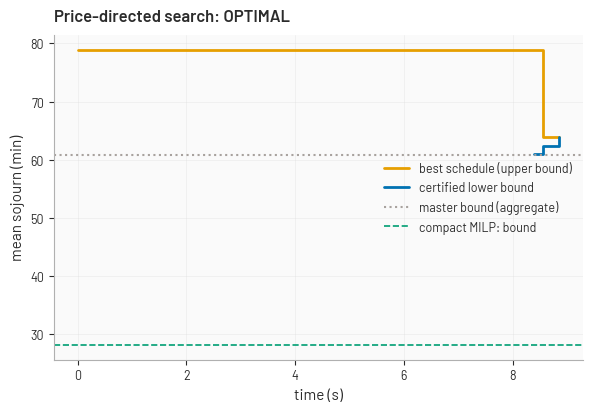

In [11]:
import random
import time

from offline_cl_opt import VehicleData
from offline_cl_PB import greedy_list_schedule
from offline_cl_opt import build_cl_model, solve_cl_model
from offline_cl_PDS.visualization import plot_bound_history, plot_slot_prices

rng = random.Random(2)
vehicles, t = [], 0.0
for i in range(15):
    Q = rng.choice([50.0, 75.0, 100.0])
    vehicles.append(VehicleData(id=i, a=round(t, 3), Q=Q, s_i=rng.uniform(0.15, 0.35),
                                s_f=rng.uniform(0.70, 0.90), s_th=0.4, p_max=2 * Q))
    t += rng.expovariate(1 / 12.0)
station, delta = StationSpec(n_piles=1, n_connectors=2, n_modules=6, p_module=25.0), 2.0

# Horizon: the greedy list schedule's makespan + 10 % (it is feasible there, so the model is too).
K_big = 10
while (greedy := greedy_list_schedule(vehicles, station, delta, K_big, {})) is None:
    K_big = int(1.3 * K_big) + 1
K_big = math.ceil(max(p.departure for p in greedy.values()) * 1.1)
horizon_big = K_big * delta
print(f"{len(vehicles)} vehicles, K={K_big} slots of {delta:g} min")

pds_big = solve_price_directed_search(vehicles, station, delta, horizon_big, time_limit=600, progress=True)

t0 = time.perf_counter()
cl_big = build_cl_model(vehicles, station, delta, horizon_big)
try:
    solve_cl_model(cl_big, mip_gap=0.0, time_limit=120)
    compact_big = extract_solution(cl_big)
    row = {"status": compact_big.status, "objective": compact_big.objective, "lower bound": compact_big.best_bound,
           "mean sojourn": compact_big.mean_sojourn}
except RuntimeError:  # no feasible schedule within the time limit
    row = {"status": "no schedule found", "objective": math.nan, "lower bound": float(cl_big.model.ObjBound),
           "mean sojourn": math.nan}
t_compact_big = time.perf_counter() - t0

display(pd.DataFrame([
    {"method": "price-directed search", "status": pds_big.status, "objective": pds_big.objective,
     "lower bound": pds_big.lower_bound, "mean sojourn": pds_big.mean_sojourn, "runtime_s": pds_big.runtime},
    {"method": "compact MILP (120 s)", **row, "runtime_s": t_compact_big},
]))
refs = {"compact MILP: bound": row["lower bound"]}
if math.isfinite(row["objective"]):
    refs["compact MILP: incumbent"] = row["objective"]
display(plot_bound_history(pds_big, references=refs))